# 02 · Explaining the model

Explanations of the churn model: what does it rely on (global), can the explanations be trusted (sanity checks) and
why is this customer at risk (local)? Using them to improve the model and to advise the business is notebook 03.
The logic lives in `src/`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when the notebook runs from notebooks/
from src.data import download, load_clean
from src.modeling import SEED, build_pipeline, make_models, split
from src.plots import FIGURES, deletion_plot, effect_plot, importance_plot, local_plot, save, use_style
from src.xai import (MAX_RANDOMIZED_SPEARMAN, RANDOM_QUANTILE, bootstrap_rows, by_original_feature, importance_under_refits,
                     linear_contributions, median_case, reference_auc_drops, shap_by_feature, shuffle_labels, top_k_vs_random_k)

use_style()

## 0. The models to explain

Same data and split as notebook 01 (seed 42), and the same two tuned models, refitted on the training set. The
explanations below describe **XGBoost**, the main model, and use **logistic regression** as a reference we can read
directly. Everything is expressed in **log-odds of churn**: a positive number pushes a customer towards churn.

In [2]:
X, y = load_clean(download())
X_train, X_test, y_train, y_test = split(X, y)

models = make_models()
final = {name: clone(models[name]).fit(X_train, y_train) for name in ("logistic", "xgboost")}
xgb, logit = final["xgboost"].best_estimator_, final["logistic"].best_estimator_
print({name: model.best_params_ for name, model in final.items()})

{'logistic': {'model__C': 10}, 'xgboost': {'model__max_depth': 1, 'model__n_estimators': 600}}


## 1. Global explanations: what does the model rely on?

We inspect the original model on the test customers. This is descriptive XAI. Because this inspection precedes the
simplification hypothesis, the later model comparison is exploratory even though its fitting and numerical selection
use training data. We do not relabel this already inspected sample as a fresh confirmatory test.

The three complementary explanatory techniques in the project are **TreeSHAP**, **permutation importance** and
**DiCE counterfactuals** (notebook 03). Here we apply the first two, with logistic regression as a separate reference:

1. **TreeSHAP on XGBoost:** additive contributions in log-odds, grouped back to the original features. Mean absolute
   contributions describe what the model uses globally; individual rows provide local explanations.
2. **Permutation importance on XGBoost:** the drop in ROC-AUC after shuffling an original feature. It measures
   dependence of a predictive metric on that feature, rather than attribution magnitude.
3. **Logistic regression contributions:** coefficient times distance from the average training customer. This is
   an intrinsically interpretable comparison model, not an explanation of XGBoost.

In [3]:
shap_values, base = shap_by_feature(xgb, X_test, X_train)             # (1,409 x 19) log-odds, XGBoost
lr_contrib, lr_base = linear_contributions(logit, X_test, X_train)    # (1,409 x 19) log-odds, logistic regression
perm = permutation_importance(xgb, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED)

importance = pd.DataFrame({
    "xgboost": shap_values.abs().mean(),
    "permutation": pd.Series(perm.importances_mean, index=X_test.columns),
    "logistic": lr_contrib.abs().mean(),
})
# The methods measure different quantities (log-odds, fall in AUC), so their magnitudes cannot be compared:
# each is expressed as a share of its own total and the comparison rests on positions.
share = (importance / importance.sum()).sort_values("xgboost", ascending=False)
print(f"Reference = the average training customer, with log-odds {base:.2f} (XGBoost) and {lr_base:.2f} (logistic)")
(share.head(10) * 100).round(1)

Reference = the average training customer, with log-odds -1.67 (XGBoost) and -1.72 (logistic)


,xgboost,permutation,logistic
Contract,19.4,29.4,6.9
tenure,17.6,43.8,15.3
InternetService,11.9,9.4,14.3
OnlineSecurity,7.0,2.7,3.1
MonthlyCharges,6.2,2.5,22.3
PaperlessBilling,5.3,1.4,2.4
MultipleLines,5.1,1.9,4.5
TechSupport,5.1,1.6,3.0
TotalCharges,5.1,4.1,6.2
PaymentMethod,5.0,1.8,2.2


In [4]:
# Permutation importance is noisy in the tail: show how much it moves between shuffles.
pd.DataFrame({"mean fall in AUC": perm.importances_mean, "std over 20 shuffles": perm.importances_std},
             index=X_test.columns).loc[share.index[:10]].round(4)

,mean fall in AUC,std over 20 shuffles
Contract,0.0457,0.0047
tenure,0.0681,0.0047
InternetService,0.0146,0.0041
OnlineSecurity,0.0041,0.0014
MonthlyCharges,0.0039,0.0021
PaperlessBilling,0.0022,0.0011
MultipleLines,0.0029,0.0012
TechSupport,0.0025,0.0012
TotalCharges,0.0064,0.0014
PaymentMethod,0.0027,0.0015


In [5]:
# Check of the reference. TreeSHAP's own base value is not an average over any data, so we recentre its
# contributions on the training customers. For an additive model that must equal interventional SHAP with
# training customers as background (slower, so here on 300 test customers and a background of 100).
prep = xgb.named_steps["prep"]
background = prep.transform(X_train.sample(100, random_state=SEED))
interventional = shap.TreeExplainer(xgb.named_steps["model"].get_booster(), data=background,
                                    feature_perturbation="interventional")(prep.transform(X_test.iloc[:300]))
by_feature = by_original_feature(interventional.values, prep.get_feature_names_out(), X_test.columns)
largest = np.abs(shap_values.iloc[:300].to_numpy() - by_feature.to_numpy()).max()
print(f"Largest difference between recentred TreeSHAP and interventional SHAP: {largest:.3f} log-odds")

Largest difference between recentred TreeSHAP and interventional SHAP: 0.068 log-odds


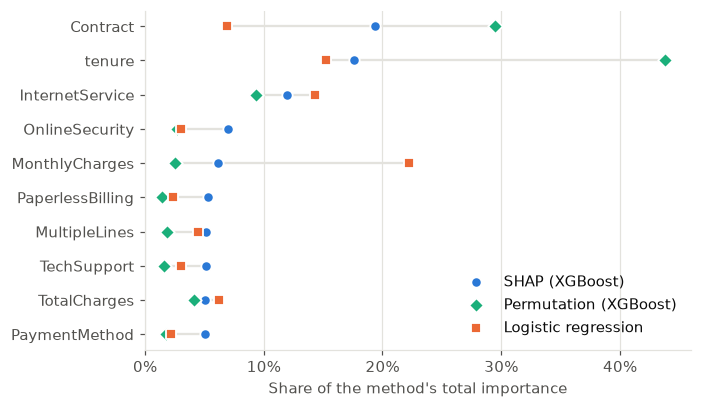

In [6]:
METHODS = {"xgboost": "SHAP (XGBoost)", "permutation": "Permutation (XGBoost)", "logistic": "Logistic regression"}
fig, ax = plt.subplots(figsize=(6.4, 4.0))
importance_plot(share.head(10), METHODS, ax)
save(fig, "importance_by_method.png")
plt.show()

**Agreement between methods.** Rank correlation (Spearman) over all 19 features, and the leading features of each
method. The tail of the permutation ranking is mostly noise (see the count below and the standard deviations above),
so the correlation over all 19 is a rough summary and the top three give a more interpretable descriptive summary, subject to the sanity checks below.

In [7]:
spearman = share.rename(columns=METHODS).corr(method="spearman")
print(f"Features with under 1 % of the permutation importance: {(share['permutation'] < 0.01).sum()} of {len(share)}")
print("Spearman rank correlation over the 19 features:"); display(spearman.round(2))
print("Top 3:", {METHODS[m]: list(share[m].nlargest(3).index) for m in share})
top5 = {METHODS[m]: set(share[m].nlargest(5).index) for m in share}
print("Features shared in the top 5:"); display(pd.DataFrame({a: {b: len(top5[a] & top5[b]) for b in top5} for a in top5}))

Features with under 1 % of the permutation importance: 9 of 19
Spearman rank correlation over the 19 features:


,SHAP (XGBoost),Permutation (XGBoost),Logistic regression
SHAP (XGBoost),1.00,0.83,0.79
Permutation (XGBoost),0.83,1.00,0.61
Logistic regression,0.79,0.61,1.00


Top 3: {'SHAP (XGBoost)': ['Contract', 'tenure', 'InternetService'], 'Permutation (XGBoost)': ['tenure', 'Contract', 'InternetService'], 'Logistic regression': ['MonthlyCharges', 'tenure', 'InternetService']}
Features shared in the top 5:


,SHAP (XGBoost),Permutation (XGBoost),Logistic regression
SHAP (XGBoost),5,4,4
Permutation (XGBoost),4,5,4
Logistic regression,4,4,5


### Detail: how each feature moves the prediction

The dot chart ranks features but hides direction. The **beeswarm** shows every test customer: horizontal position is
the contribution of the feature to that customer's log-odds, colour is the feature value. Yes/No features are coded
1/0 and Contract by length (month-to-month 0, one year 1, two years 2); the other text features have no natural
order and are grey.

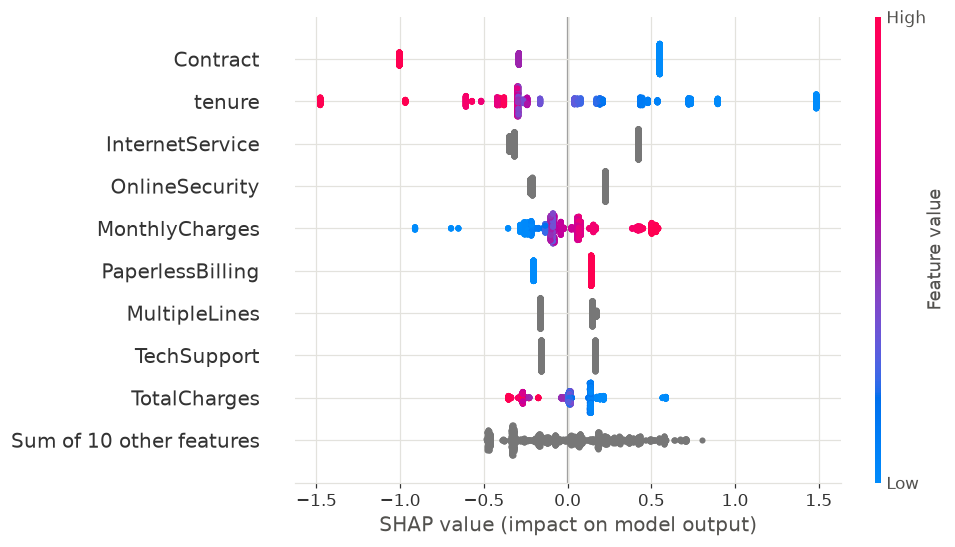

In [8]:
coded = X_test.copy()   # numbers as they are, Yes/No as 1/0, other text features left empty (grey)
for column in X_test.select_dtypes(exclude="number"):
    levels = sorted(X_test[column].unique())
    coded[column] = X_test[column].map({levels[0]: 0, levels[1]: 1}) if len(levels) == 2 else np.nan
coded["Contract"] = X_test["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
explanation = shap.Explanation(values=shap_values.to_numpy(), base_values=np.full(len(X_test), base),
                               data=coded.to_numpy(dtype=float), feature_names=list(X_test.columns))
with warnings.catch_warnings():
    # Expected: text features with more than two levels have no colour scale (all values empty), so numpy
    # warns while shap computes the colour range. They are drawn grey on purpose.
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    shap.plots.beeswarm(explanation, max_display=10, show=False)
plt.show()

**Shape of the effect.** For the two numeric features that matter most, XGBoost's contribution (dots) against the
straight line the logistic regression is forced to draw. Both are relative to the same reference customer.

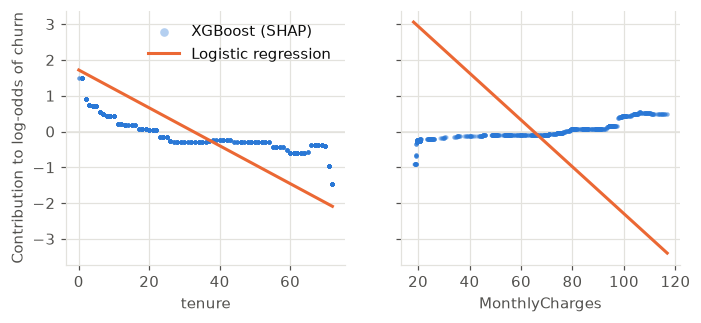

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
for ax, feature in zip(axes, ["tenure", "MonthlyCharges"]):
    effect_plot(X_test[feature], shap_values[feature], lr_contrib[feature], ax, feature)
axes[0].set_ylabel("Contribution to log-odds of churn")
axes[0].legend(loc="upper right", markerscale=2)
save(fig, "effects_numeric.png")
plt.show()

In [10]:
# The tenure curve in numbers (mean contribution of each band, log-odds; positive = towards churn).
bands = pd.cut(X_test["tenure"], [-1, 1, 3, 6, 12, 24, 48, 71, 72],
               labels=["0-1", "2-3", "4-6", "7-12", "13-24", "25-48", "49-71", "72"])
shap_values["tenure"].groupby(bands, observed=True).agg(["mean", "size"]).round(2)

,mean,size
tenure,,
0-1,1.48,129
2-3,0.82,101
4-6,0.67,81
7-12,0.39,138
13-24,0.05,206
25-48,-0.27,304
49-71,-0.48,380
72,-1.48,70


In [11]:
# Categorical features: average contribution of each level (log-odds; positive = towards churn).
levels = pd.concat({feature: shap_values[feature].groupby(X_test[feature]).agg(["mean", "size"])
                    for feature in ["Contract", "InternetService", "OnlineSecurity", "PaymentMethod", "TechSupport"]})
levels.round(2)

mean  size
Contract        Month-to-month             0.55   773
                One year                  -0.29   300
                Two year                  -1.00   336
InternetService DSL                       -0.32   484
                Fiber optic                0.42   613
                No                        -0.35   312
OnlineSecurity  No                         0.22   701
                No internet service       -0.23   312
                Yes                       -0.21   396
PaymentMethod   Bank transfer (automatic) -0.12   300
                Credit card (automatic)   -0.12   309
                Electronic check           0.23   474
                Mailed check              -0.12   326
TechSupport     No                         0.16   702
                No internet service       -0.16   312
                Yes                       -0.16   395

In [12]:
# Is the price independent information? How well do the contracted services alone predict MonthlyCharges?
services = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
r2 = cross_val_score(build_pipeline(LinearRegression()), X_train[services], X_train["MonthlyCharges"],
                     cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2")
print(f"MonthlyCharges predicted from the services alone: CV R2 = {r2.mean():.3f}")
print("Contribution of MonthlyCharges, min / max (log-odds):")
print("  logistic regression:", lr_contrib["MonthlyCharges"].agg(["min", "max"]).round(2).tolist())
print("  XGBoost (SHAP):     ", shap_values["MonthlyCharges"].agg(["min", "max"]).round(2).tolist())
coefficient = dict(zip(logit.named_steps["prep"].get_feature_names_out(), logit.named_steps["model"].coef_[0]))
print(f"Correlation of MonthlyCharges with churn (train): {X_train['MonthlyCharges'].corr(y_train):+.2f}; "
      f"logistic coefficient of standardised MonthlyCharges: {coefficient['num__MonthlyCharges']:+.2f}")
print(f"Correlation of tenure with TotalCharges (train): {X_train['tenure'].corr(X_train['TotalCharges']):.2f}")

MonthlyCharges predicted from the services alone: CV R2 = 0.999
Contribution of MonthlyCharges, min / max (log-odds):
  logistic regression: [-3.4, 3.06]
  XGBoost (SHAP):      [-0.91, 0.54]
Correlation of MonthlyCharges with churn (train): +0.20; logistic coefficient of standardised MonthlyCharges: -1.97
Correlation of tenure with TotalCharges (train): 0.83


### Reading section 1

**Reference.** All contributions are relative to the average training customer (log-odds -1.67 for XGBoost, -1.72
for the logistic regression). TreeSHAP's own base value is not an average over any data (it corresponds to 26 % churn
and is only a coincidence with the churn rate), so we recentre its contributions on the training customers. For this
additive model that matches interventional SHAP to within the largest difference printed above, small against
contributions of about +-1 log-odds.

**Where the methods agree.** SHAP and permutation importance, both on XGBoost, share their top three (Contract,
tenure, InternetService) and correlate at 0.83 over the 19 features. The logistic regression shares tenure and
InternetService with them, and correlates at 0.79 with SHAP and 0.61 with permutation. Every pair has four of its top
five in common. Beyond the top three the permutation ranking is mostly noise: the permutation importance of OnlineSecurity and
MonthlyCharges (0.0041 +- 0.0014 and 0.0039 +- 0.0021) cannot be told apart.

**Where they disagree, and why it matters.**

1. *Which feature is first depends on the method.* SHAP puts Contract first, by a small margin (19.4 % against
   17.6 % for tenure); permutation puts tenure first, well ahead within that method (43.8 % against 29.4 %); the
   logistic regression puts MonthlyCharges first (22.3 %) and Contract only fourth. SHAP measures how far the
   model's outputs move because of a feature, permutation how much the AUC falls without it: different questions,
   different answers. The linear ranking needs care: it describes a different model and its price contribution is affected by near-collinearity.
2. *For MonthlyCharges, collinearity flips the sign.* The contracted services alone predict it with a
   cross-validated R2 of 0.999, so it is almost reconstructible. This does not prove that its residual carries no target information; the ablation in notebook 03 tests its practical dispensability. Its marginal correlation with churn is
   positive (+0.20: the more expensive, the more churn), but the standardised logistic coefficient is -1.97:
   *given the services*, the sign reverses, and its contribution ranges from -3.4 to +3.1 log-odds against -0.91 to
   +0.54 in XGBoost. The reversal is consistent with conditioning and near-collinearity; it is not an identified causal price effect. It must not be read as
   a pricing insight.
3. *Correlated features share and duplicate credit.* Tenure and TotalCharges correlate at 0.83. Customers without
   internet service receive a negative contribution from add-on features such as OnlineSecurity (-0.23) and TechSupport (-0.16) on top of the -0.35 of InternetService itself: related profile information receives contributions through several predictors; these are not independent causal effects.

**The effects are not linear.** XGBoost's contribution of tenure falls from +1.48 log-odds in the first two months to
+0.67 (months 4-6), +0.39 (7-12), about 0 (13-24), -0.27 (25-48) and -0.48 (49-71): steep in the first year, then
slow. The logistic regression can only draw a straight line. The jump to -1.48 at tenure 72 (the largest value in the
data, 70 customers) is the model reading the edge of the range, and we do not interpret it as a real effect.
Because the best model is made of depth-1 trees it is additive, so each feature has a single curve (the dots of the
figure trace one line) and there are no interactions to explain.

**Direction, by level** (average contribution, log-odds): month-to-month contracts +0.55 against -0.29 (one year)
and -1.00 (two years); fibre optic +0.42 against -0.32 (DSL) and -0.35 (no internet); electronic check +0.23 against
-0.12 for the other three payment methods. These are differences in what the *model predicts* between groups of
customers. They do not say that moving a customer to another contract would change their behaviour.

**To carry forward.** (i) MonthlyCharges (R2 0.999 with the services) and probably TotalCharges (r = 0.83 with
tenure) look redundant: a hypothesis for the exploratory model-improvement section, with redundancy and numerical selection evaluated on training data.
(ii) Rankings beyond the top three are noisy, and the "top driver" depends on the method, so the explanations
themselves need testing.

## 2. Do the explanations pass sanity checks?

The original diagnostic criteria are retained: shuffled-label mean Spearman below 0.5, and top-k AUC loss above the
95th percentile of a reference of k-feature subsets, for k = 1, 2, 3. These are diagnostic rules, not calibrated
significance tests or proof of causal validity. The subset reference was strengthened after the exploratory audit:

1. **Label randomisation.** Refit 10 times on shuffled labels. Compare the resulting importance rankings with the
   original and with 10 bootstrap refits that retain labels. This separates label sensitivity from ordinary refit noise.
2. **Feature shuffling.** Rankings come from training. Enumerate all 19 singleton subsets (50 permutations each)
   and all 171 pairs (10 each); for triples sample 200 distinct subsets without replacement (10 each). Each subset
   has the same seeded perturbations wherever it is used, and every ranking shares the same reference. Compare
   SHAP, permutation and logistic rankings on XGBoost, plus reversed SHAP as a negative control.

Exhaustive means exhaustive feature subsets; each estimated AUC drop still has finite permutation noise. We report
failures as well as passes and do not change the original 0.95 criterion to obtain a preferred verdict.

In [13]:
CHECKED_K = (1, 2, 3)                                    # fixed before running the checks
real_ranking = importance["xgboost"]                     # mean |SHAP| of the real model on the test set
make_model = lambda: clone(xgb)                          # unfitted pipeline with the tuned hyperparameters

shuffled = importance_under_refits(make_model, X_train, y_train, X_test, shuffle_labels, n_refits=10)
resampled = importance_under_refits(make_model, X_train, y_train, X_test, bootstrap_rows, n_refits=10)
spearman_with_real = pd.DataFrame({
    "shuffled labels": shuffled.apply(lambda row: row.corr(real_ranking, method="spearman"), axis=1),
    "resampled rows (control)": resampled.apply(lambda row: row.corr(real_ranking, method="spearman"), axis=1),
})
display(spearman_with_real.agg(["mean", "min", "max"]).round(2))
verdict = "PASS" if spearman_with_real["shuffled labels"].mean() < MAX_RANDOMIZED_SPEARMAN else "FAIL"
print(f"Rule 1: mean Spearman with shuffled labels < {MAX_RANDOMIZED_SPEARMAN}  ->  {verdict}")

one_shuffle = make_model().fit(X_train, np.random.default_rng(SEED).permutation(np.asarray(y_train)))
print(f"Test ROC-AUC of a model fitted on shuffled labels: {roc_auc_score(y_test, one_shuffle.predict_proba(X_test)[:, 1]):.3f}")
print("Features that a model with no signal still ranks highest (mean |SHAP|):", list(shuffled.mean().nlargest(4).index))
print(f"Total mean |SHAP| of the shuffled models: {shuffled.sum(axis=1).mean():.2f}, against {real_ranking.sum():.2f} for the real model")

,shuffled labels,resampled rows (control)
mean,0.31,0.92
min,0.04,0.86
max,0.60,0.97


Rule 1: mean Spearman with shuffled labels < 0.5  ->  PASS


Test ROC-AUC of a model fitted on shuffled labels: 0.517
Features that a model with no signal still ranks highest (mean |SHAP|): ['TotalCharges', 'MonthlyCharges', 'tenure', 'PaymentMethod']
Total mean |SHAP| of the shuffled models: 0.46, against 3.12 for the real model


In [14]:
CHECKED_K, REFERENCE_BUDGET = (1, 2, 3), 200
rankings = {
    "xgboost": shap_by_feature(xgb, X_train, X_train)[0].abs().mean(),
    "permutation": pd.Series(permutation_importance(xgb, X_train, y_train, scoring="roc_auc", n_repeats=10,
                                                    random_state=SEED).importances_mean, index=X_train.columns),
    "logistic": linear_contributions(logit, X_train, X_train)[0].abs().mean(),
}
ordered_rankings = {name: list(scores.sort_values(ascending=False).index) for name, scores in rankings.items()}
ordered_rankings["reversed"] = ordered_rankings["xgboost"][::-1]
rows = []
for k in CHECKED_K:
    repeats = 50 if k == 1 else 10
    reference = reference_auc_drops(xgb, X_test, y_test, X_train.columns, k,
                                    n_random=REFERENCE_BUDGET, n_repeats=repeats)
    for name, ordered in ordered_rankings.items():
        top, random = top_k_vs_random_k(xgb, X_test, y_test, ordered, k, n_repeats=repeats, reference=reference)
        rows.append({"ranking": name, "k": k, "top_k_drop": top, "random_median": np.median(random),
                     "random_low": np.quantile(random, 0.05), "random_high": np.quantile(random, RANDOM_QUANTILE),
                     "reference_subsets": len(reference), "permutations_per_subset": repeats,
                     "passes": bool(top > np.quantile(random, RANDOM_QUANTILE))})
deletion = pd.DataFrame(rows)
display(deletion.pivot(index="k", columns="ranking", values="top_k_drop").round(4))
display(deletion[deletion["ranking"] == "xgboost"].set_index("k")[["reference_subsets", "random_median", "random_high"]].round(4))
print("Rule 2 (every k must pass):", deletion.groupby("ranking")["passes"].all().to_dict())
initial_checks = {
    "protocol": {"reference_budget": REFERENCE_BUDGET, "criterion_quantile": RANDOM_QUANTILE,
                 "single_feature_permutations": 50, "other_permutations": 10,
                 "status": "reference strengthened after exploratory audit; original diagnostic thresholds retained"},
    "label_randomisation": {
        "mean_shuffled_spearman": float(spearman_with_real["shuffled labels"].mean()),
        "mean_control_spearman": float(spearman_with_real["resampled rows (control)"].mean()),
        "min_shuffled_spearman": float(spearman_with_real["shuffled labels"].min()),
        "max_shuffled_spearman": float(spearman_with_real["shuffled labels"].max()),
        "shuffled_test_auc": float(roc_auc_score(y_test, one_shuffle.predict_proba(X_test)[:, 1])),
        "randomised_total_attribution": float(shuffled.sum(axis=1).mean()),
        "original_total_attribution": float(real_ranking.sum()),
    },
    "deletion": deletion.to_dict("records"),
}
(FIGURES.parent / "xai_checks_initial.json").write_text(json.dumps(initial_checks, indent=2, allow_nan=False))

ranking,logistic,permutation,reversed,xgboost
k,,,,
1,0.0039,0.0673,0.0,0.0453
2,0.0617,0.1510,0.0,0.1510
3,0.0978,0.1882,-0.0,0.1882


,reference_subsets,random_median,random_high
k,,,
1,19,0.0015,0.0475
2,171,0.0046,0.0662
3,200,0.0094,0.0838


Rule 2 (every k must pass): {'logistic': False, 'permutation': True, 'reversed': False, 'xgboost': False}


4443

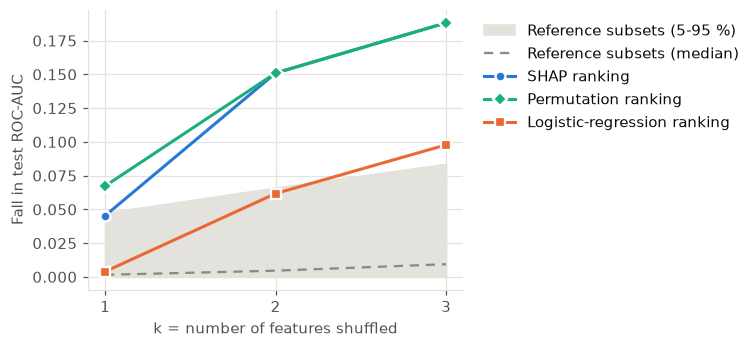

In [15]:
fig, ax = plt.subplots(figsize=(4.4, 3.3))
deletion_plot(deletion, {"xgboost": "SHAP ranking", "permutation": "Permutation ranking", "logistic": "Logistic-regression ranking"}, ax)
save(fig, "sanity_deletion.png")
plt.show()

### Reading section 2

**Label randomisation is passed, with a caveat.** Mean Spearman is about 0.31 with shuffled labels versus 0.92 for
bootstrap controls. The shuffled model has test AUC 0.517 and its total attribution is about 15 % of the original.
The remaining correlation is compatible with splitting opportunities and feature types influencing even noise models.

**The strengthened deletion reference exposes a failure at k = 1.** SHAP ranks Contract first, but tenure is more
necessary for ROC-AUC. With all 19 singleton subsets and 50 permutations each, Contract costs about 0.0453 of AUC,
below the 95th percentile of about 0.0475. The earlier pass from 30 sampled sets was fragile. The table above reports
the strengthened k = 2 and 3 results and all ranking-level verdicts; one failed k means the complete criterion fails.

**What this tests.** AUC reliance and attribution magnitude are different quantities. The logistic ranking describes
another model; applying it to XGBoost is a comparison and negative-control exercise, not a verdict on logistic explanations.
Permutation importance is favoured by construction because it targets the same metric loss used by this check.

**Limits.** Triples are still sampled, the score of every subset has permutation noise, and independent shuffling can
create unrealistic combinations of correlated services. Retained correlated variables may also compensate for a
shuffled variable. Passing does not validate attribution signs, magnitudes, local robustness or causal interventions.
The adopted 17-feature model is evaluated separately in notebook 03.

## 3. Local explanations: why is this customer at risk?

The global view says what the model relies on *on average*; the retention team needs the reason for *one*
customer. **SHAP** gives it exactly: the contributions of one row add up to that customer's log-odds, starting from the
average training customer. We look at three typical cases at the operating threshold chosen in notebook 01
(ratio 5): the customer at the **median probability** of each group, to avoid picking extreme, unrepresentative
ones. A: a churner the model flags. B: a churner it misses. C: a loyal customer it flags (a wasted offer).

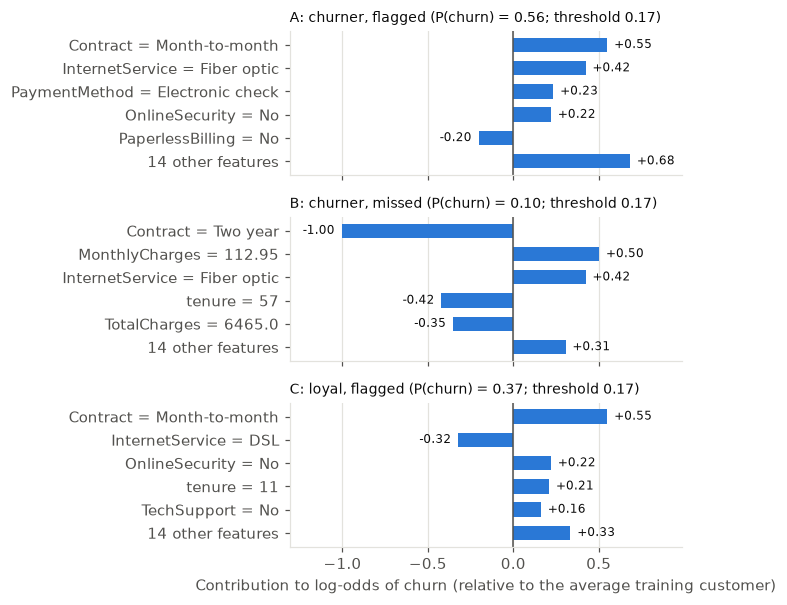

Threshold in log-odds: -1.59 | average training customer: -1.67


,"A: churner, flagged","B: churner, missed","C: loyal, flagged"
gender,Female,Female,Female
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,13,57,11
PhoneService,Yes,Yes,Yes
MultipleLines,Yes,Yes,Yes
InternetService,Fiber optic,Fiber optic,DSL
OnlineSecurity,No,Yes,No
OnlineBackup,Yes,Yes,No


In [16]:
metrics = json.loads((FIGURES.parent / "metrics.json").read_text())
threshold = metrics["thresholds"]["5"]["xgboost"]            # chosen on out-of-fold train predictions (notebook 01)
proba = xgb.predict_proba(X_test)[:, 1]
flagged, churned = proba >= threshold, np.asarray(y_test) == 1
cases = {"A: churner, flagged": median_case(proba, flagged & churned),
         "B: churner, missed": median_case(proba, ~flagged & churned),
         "C: loyal, flagged": median_case(proba, flagged & ~churned)}

fig, axes = plt.subplots(3, 1, figsize=(6.4, 5.6), sharex=True)
for ax, (title, position) in zip(axes, cases.items()):
    local_plot(shap_values.iloc[position], X_test.iloc[position], ax)
    ax.set_title(f"{title} (P(churn) = {proba[position]:.2f}; threshold {threshold:.2f})", loc="left", fontsize=9)
axes[-1].set_xlabel("Contribution to log-odds of churn (relative to the average training customer)")
fig.tight_layout()
save(fig, "local_cases.png")
plt.show()
print("Threshold in log-odds:", round(float(np.log(threshold / (1 - threshold))), 2), "| average training customer:", round(base, 2))
X_test.iloc[list(cases.values())].T.set_axis(list(cases), axis=1)

### Reading section 3

Each bar chart is a story from left to right: it starts at the average training customer (log-odds -1.67) and adds
the contribution of each feature up to this customer's score. The operating threshold (log-odds -1.59) sits barely
above that average customer, because at a cost ratio of 5 it is cheap to contact a customer who might leave.

- **A, a typical churner the model flags** (P = 0.56). Pushed up by a month-to-month contract (+0.55), fibre optic
  (+0.42), electronic check (+0.23) and no online security (+0.22): the profile of the global picture. Contract, payment method and online security suggest candidate offers for the next notebook; acceptance and causal effects still require investigation.
- **B, a typical churner the model misses** (P = 0.10). A two-year contract (-1.00), 57 months of tenure (-0.42) and a
  large accumulated bill (-0.35) outweigh a high monthly charge and fibre optic (+0.50, +0.42). The explanation shows
  *why the model missed this customer*: every loyalty marker points the other way, and the available features say
  nothing else. Complaints or a competitor's offer are plausible unobserved factors, but a false negative alone does not show that the reason is absent from the data; some churn is expected even among customers scored at 0.10.
- **C, a typical wasted offer** (P = 0.37). Flagged by a month-to-month contract (+0.55) and the absence of add-ons
  (+0.22, +0.16), with DSL (-0.32) as the only mitigating factor. This customer looks like a churner and stayed: an
  error the model makes by design at this threshold.

**Limits.** SHAP explains the model's score, not the reason the customer left, and every number is relative to the
average training customer and to this model. Case B also shows contributions for MonthlyCharges (+0.50) and
TotalCharges (-0.35) although both are redundant, the credit-splitting problem of notebook 02: the model-improvement
section tests whether removing them makes such explanations cleaner.